In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import plotly.express as px
import numpy as np

pd.options.mode.chained_assignment = None

In [5]:
path_files = r"C:\Users\eduque\Fraunhofer\DeV-KopSys-2 - Globale ESA\01_countries\DevKopSysII_v2.0\results_v0.2_deadline_October\energy_base_totals\xlsx_per_country"
files = [
    ("demands_MA_v2.xlsx", "csv_pypsa"),
    ("demands_CL_v2.xlsx", "csv_pypsa"),
    ("demands_EG_v2.xlsx", "csv_pypsa"),
    ("demands_ZA_v2.xlsx", "csv_pypsa")
]

dfs = []
for file, sheet in files:
    file_path = os.path.join(path_files, file)
    df = pd.read_excel(file_path, sheet_name=sheet)
    dfs.append(df)

# Concatenate all DataFrames into one
df = pd.concat(dfs, ignore_index=True)


In [6]:
# Residential Balance

#set correct indexes
df.set_index(['scenario',"country"], inplace=True)

columns_residential = [
    "scenario",
    "country",
    "electricity", 
    "biomass", 
    "gas", 
    "liq. hydrocarbons"
]

dfs = []
for file, sheet in files:
    file_path = os.path.join(path_files, file)
    df = pd.read_excel(file_path, sheet_name=sheet)
    df= df.rename(columns={
        "electricity residential": "electricity",
        "residential oil": "liq. hydrocarbons",
        "residential biomass": "biomass",
        "residential gas": "gas"
        }, inplace=False)
    df= df[columns_residential]
    df = df[df['scenario'] != 'base']
    df = df.drop(1).reset_index(drop=True)
    dfs.append(df)

# Create a dictionary mapping country code to DataFrame
country_dfs = {df["country"].iloc[0].lower(): df for df in dfs}

# Example usage:
df_ma = country_dfs["ma"]
df_cl = country_dfs["cl"]
df_eg = country_dfs["eg"]
df_za = country_dfs["za"]

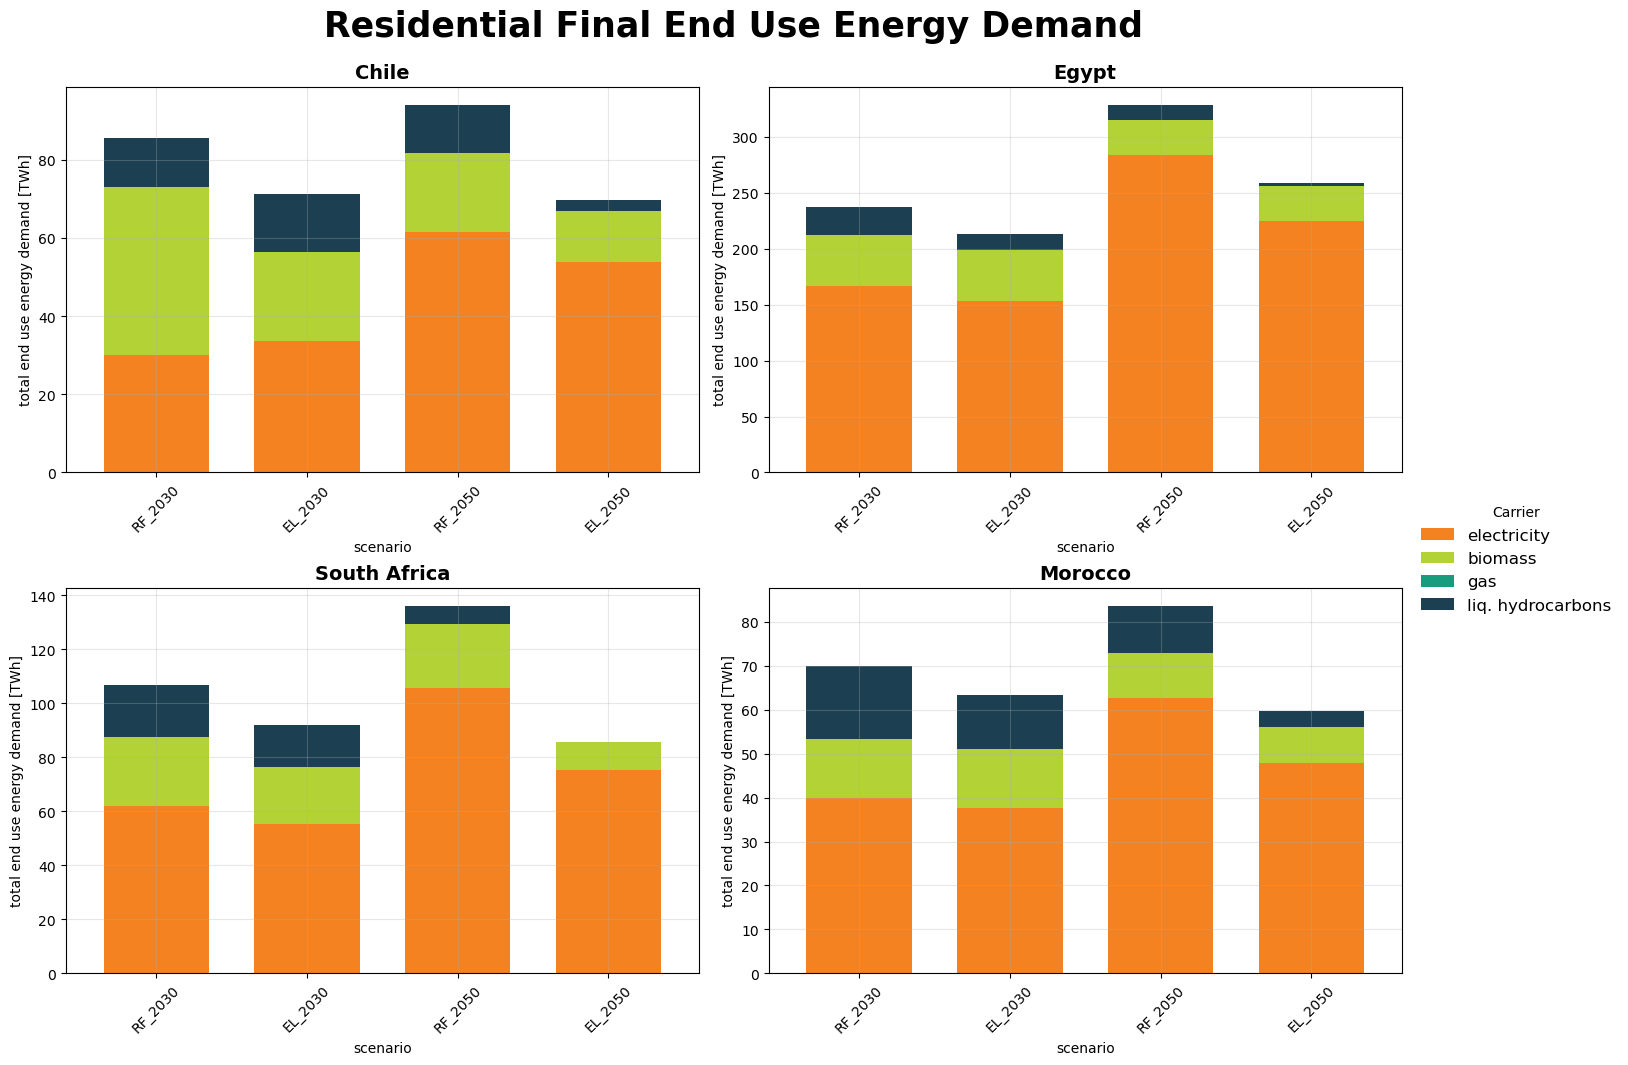

In [7]:

# graphic option A
scenario_order = ['RF_2030', 'EL_2030', 'RF_2050', 'EL_2050'] #"base",

# Colors for residential carriers
residential_colors = {
    'electricity': '#f58220', # Orange
    'biomass': '#b2d235', # Green
    'gas': '#179c7d', # Blue-grey
    'liq. hydrocarbons': '#1c3f52', # Dark blue
}
residential_cols = list(residential_colors.keys())

# Make sure scenario is categorical and ordered for all dfs
for df in [df_za, df_ma, df_cl, df_eg]:
    df['scenario'] = pd.Categorical(df['scenario'], categories=scenario_order, ordered=True)

def plot_residential_bar(df, country_name, ax):
    df_sorted = df.sort_values('scenario')
    df_pivot = df_sorted.set_index('scenario')[residential_cols]
    colors = [residential_colors[col] for col in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, legend=False, stacked=True, width=0.7)
    ax.set_title(country_name, fontsize=14, weight='bold')
    #ax.set_xlabel('Scenario')
    ax.set_ylabel('total end use energy demand [TWh]')
    ax.grid(alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

fig, axs = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

plot_residential_bar(df_cl, 'Chile', axs[0, 0])
plot_residential_bar(df_eg, 'Egypt', axs[0, 1])
plot_residential_bar(df_za, 'South Africa', axs[1, 0])
plot_residential_bar(df_ma, 'Morocco', axs[1, 1])

fig.suptitle('Residential Final End Use Energy Demand', fontsize=25, weight='bold', y=1.05, x=0.52)
handles, labels = axs[0,0].get_legend_handles_labels()
fig.legend(handles, labels, title='Carrier', loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='large', frameon=False)
fig.savefig("Residential_demand_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()

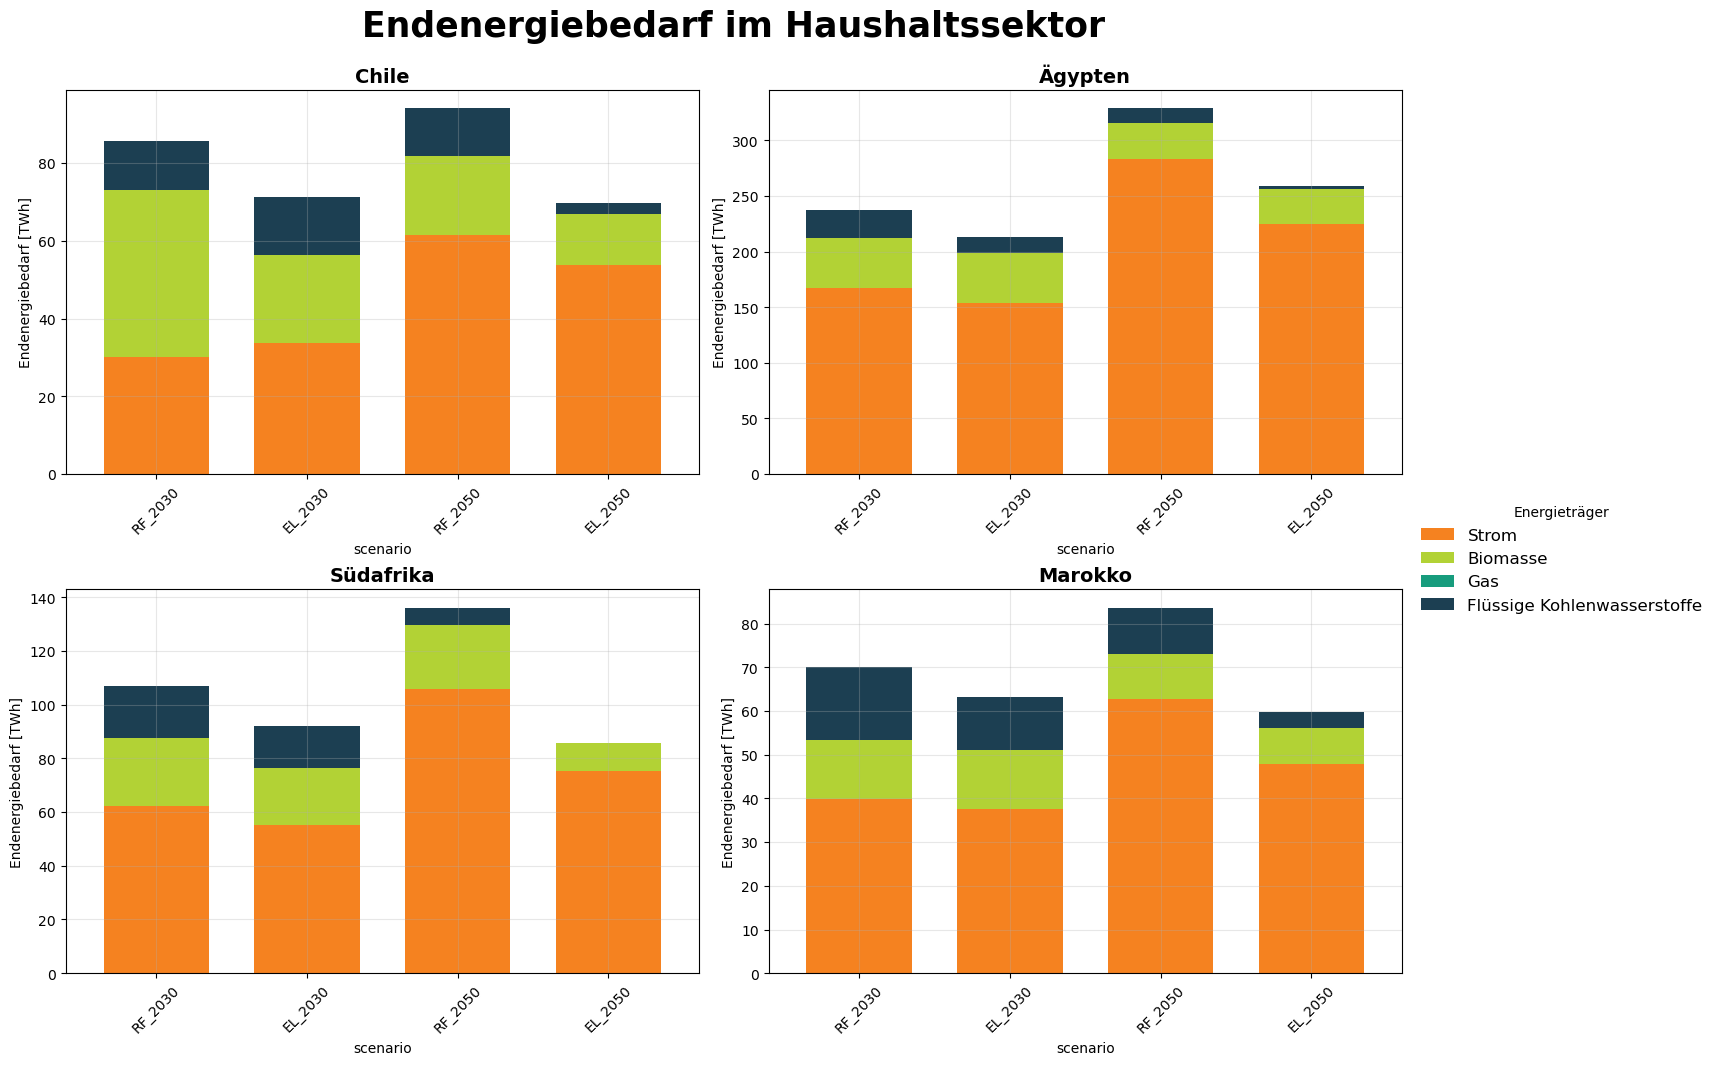

In [8]:
# German mapping for carriers
carrier_legend_de = {
    'electricity': 'Strom',
    'biomass': 'Biomasse',
    'gas': 'Gas',
    'liq. hydrocarbons': 'Flüssige Kohlenwasserstoffe'
}

# Update y-axis label to German
y_axis_label_de = 'Endenergiebedarf [TWh]'

def plot_residential_bar(df, country_name, ax):
    df_sorted = df.sort_values('scenario')
    df_pivot = df_sorted.set_index('scenario')[residential_cols]
    colors = [residential_colors[col] for col in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, legend=False, stacked=True, width=0.7)
    ax.set_title(country_name, fontsize=14, weight='bold')
    # Removed x-axis label as requested
    ax.set_ylabel(y_axis_label_de)
    ax.grid(alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

fig, axs = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

plot_residential_bar(df_cl, 'Chile', axs[0, 0])
plot_residential_bar(df_eg, 'Ägypten', axs[0, 1])
plot_residential_bar(df_za, 'Südafrika', axs[1, 0])
plot_residential_bar(df_ma, 'Marokko', axs[1, 1])

fig.suptitle('Endenergiebedarf im Haushaltssektor', fontsize=25, weight='bold', y=1.05, x=0.52)
handles, labels = axs[0,0].get_legend_handles_labels()
labels_de = [carrier_legend_de.get(label, label) for label in labels]
fig.legend(handles, labels_de, title='Energieträger', loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='large', frameon=False)
fig.savefig("Residential_demand_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()

In [9]:
# Technologies for residential
path_file = r'C:\Users\eduque\Fraunhofer\DeV-KopSys-2 - Globale ESA\04_methods_and_models\Sectoral_End-Use_Energy_Scenario\graphics\input_data'
df = pd.read_excel(os.path.join(path_file, 'residential_all_280825.xlsx'))
df = df[~df['carrier'].isin(["Coal",'Heat', 'Renewable Heat (Solar & Geothermal)'])]
df.drop(columns= "Residential Total", inplace =True, axis=1)
df["carrier"].replace({
    'Oil': "liq. hydrocarbons",
    'Gas': "gas",
    'Electricity': "electricity", 
    'Hydrogen': "hydrogen", 
    'Biomass': "biomass"
    }, inplace=True)
df.fillna(0, inplace=True)
df

C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\2525176795.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["carrier"].replace({


,country,scenario,carrier,Residential Space Heating,Residential Space Cooling,Residential Water Heating,Residential Cooking,Residential Electrical Appliances
0,ZA,RF_2030,liq. hydrocarbons,6.235223,0.000000,12.873201,0.000000,0.000000
1,ZA,RF_2030,gas,0.000000,0.000000,0.000000,0.000000,0.000000
3,ZA,RF_2030,electricity,6.519475,22.639885,13.460068,6.769072,12.743290
4,ZA,RF_2030,hydrogen,0.000000,0.000000,0.000000,0.000000,0.000000
6,ZA,RF_2030,biomass,2.750834,0.000000,5.679354,17.093615,0.000000
...,...,...,...,...,...,...,...,...
120,EG,EL_2050,liq. hydrocarbons,0.000000,0.000000,0.000000,3.130863,0.000000
121,EG,EL_2050,gas,0.000000,0.000000,0.000000,0.000000,0.000000
123,EG,EL_2050,electricity,64.729086,75.551586,28.019955,16.084452,40.373598
124,EG,EL_2050,hydrogen,0.000000,0.000000,0.000000,0.000000,0.000000


In [10]:
# Technologies for residential
path_file = r'C:\Users\eduque\Fraunhofer\DeV-KopSys-2 - Globale ESA\04_methods_and_models\Sectoral_End-Use_Energy_Scenario\graphics\input_data'
df = pd.read_excel(os.path.join(path_file, 'residential_all_280825.xlsx'))
df = df[~df['carrier'].isin(["Coal",'Heat', 'Renewable Heat (Solar & Geothermal)'])]
df.drop(columns= "Residential Total", inplace =True, axis=1)
df["carrier"].replace({
    'Oil': "liq. hydrocarbons",
    'Gas': "gas",
    'Electricity': "electricity", 
    'Hydrogen': "hydrogen", 
    'Biomass': "biomass"
    }, inplace=True)
df.fillna(0, inplace=True)

df_residential = df.copy()

df_residential.rename(columns={
    'Residential Space Heating': 'space heating',
    'Residential Space Cooling': 'space cooling',
    'Residential Water Heating': 'water heating',
    'Residential Cooking': 'cooking',
    'Residential Electrical Appliances': 'electrical appliances',
}, inplace=True)

tech_cols = [
    'space heating',
    'space cooling',
    'water heating',
    'cooking',
    'electrical appliances'
]

df_long = df_residential.melt(
    id_vars=['country', 'scenario', 'carrier'],
    value_vars=tech_cols,
    var_name='technology',
    value_name='value'
)


df_long

C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\2542611606.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["carrier"].replace({


,country,scenario,carrier,technology,value
0,ZA,RF_2030,liq. hydrocarbons,space heating,6.235223
1,ZA,RF_2030,gas,space heating,0.000000
2,ZA,RF_2030,electricity,space heating,6.519475
3,ZA,RF_2030,hydrogen,space heating,0.000000
4,ZA,RF_2030,biomass,space heating,2.750834
...,...,...,...,...,...
395,EG,EL_2050,liq. hydrocarbons,electrical appliances,0.000000
396,EG,EL_2050,gas,electrical appliances,0.000000
397,EG,EL_2050,electricity,electrical appliances,40.373598
398,EG,EL_2050,hydrogen,electrical appliances,0.000000


In [11]:
# Filter for space heating, electricity carrier, and scenario EL_2050
mask = (
    (df_long['technology'] == 'space heating') &
    (df_long['carrier'] == 'electricity') &
    (df_long['scenario'] == 'EL_2050')
)

# Aggregate electricity value for space heating in EL_2050 across all countries
el_space_heating = df_long[mask].groupby('country')['value'].sum()

# Aggregate total space heating demand (all carriers) for EL_2050 across all countries
total_mask = (
    (df_long['technology'] == 'space heating') &
    (df_long['scenario'] == 'EL_2050')
)
total_space_heating = df_long[total_mask].groupby('country')['value'].sum()

# Calculate share for each country
share_space_heating_el = (el_space_heating / total_space_heating * 100).round(1)

# Display result
print("Elektrifizierungsanteil für space heating im Szenario EL_2050 (%):")
print(share_space_heating_el)
print("Durchschnitt aller Länder: {:.1f} %".format(share_space_heating_el.mean()))

Elektrifizierungsanteil für space heating im Szenario EL_2050 (%):
country
CL    62.3
EG    94.5
MA    73.6
ZA    90.6
Name: value, dtype: float64
Durchschnitt aller Länder: 80.2 %


In [12]:
# Aggregate all carriers for each technology, country, and scenario
df_agg = df_long.groupby(['country', 'scenario', 'technology'], as_index=False)['value'].sum()

# Calculate total value per country and scenario (across all technologies)
total_per_scenario = df_agg.groupby(['country', 'scenario'])['value'].transform('sum')

# Calculate share for each technology
df_agg['share'] = df_agg['value'] / total_per_scenario

# Create a pivot table for easier viewing (optional)
df_shares = df_agg.pivot_table(
    index=['country', 'scenario'],
    columns='technology',
    values='share'
).reset_index()

df_shares

technology,country,scenario,cooking,electrical appliances,space cooling,space heating,water heating
0,CL,EL_2030,0.084137,0.232870,0.100402,0.439327,0.143263
1,CL,EL_2050,0.091410,0.258222,0.147439,0.388441,0.114489
2,CL,RF_2030,0.067177,0.185929,0.046703,0.544088,0.156103
3,CL,RF_2050,0.066339,0.185803,0.132999,0.471952,0.142907
4,EG,EL_2030,0.187628,0.150224,0.318409,0.230358,0.113381
5,EG,EL_2050,0.168058,0.155673,0.291313,0.264008,0.120948
6,EG,RF_2030,0.163130,0.130610,0.322572,0.225941,0.157747
7,EG,RF_2050,0.107160,0.122298,0.382544,0.269292,0.118707
8,MA,EL_2030,0.195273,0.156345,0.285912,0.135501,0.226969
9,MA,EL_2050,0.181800,0.162254,0.295218,0.207759,0.152968


C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence thi

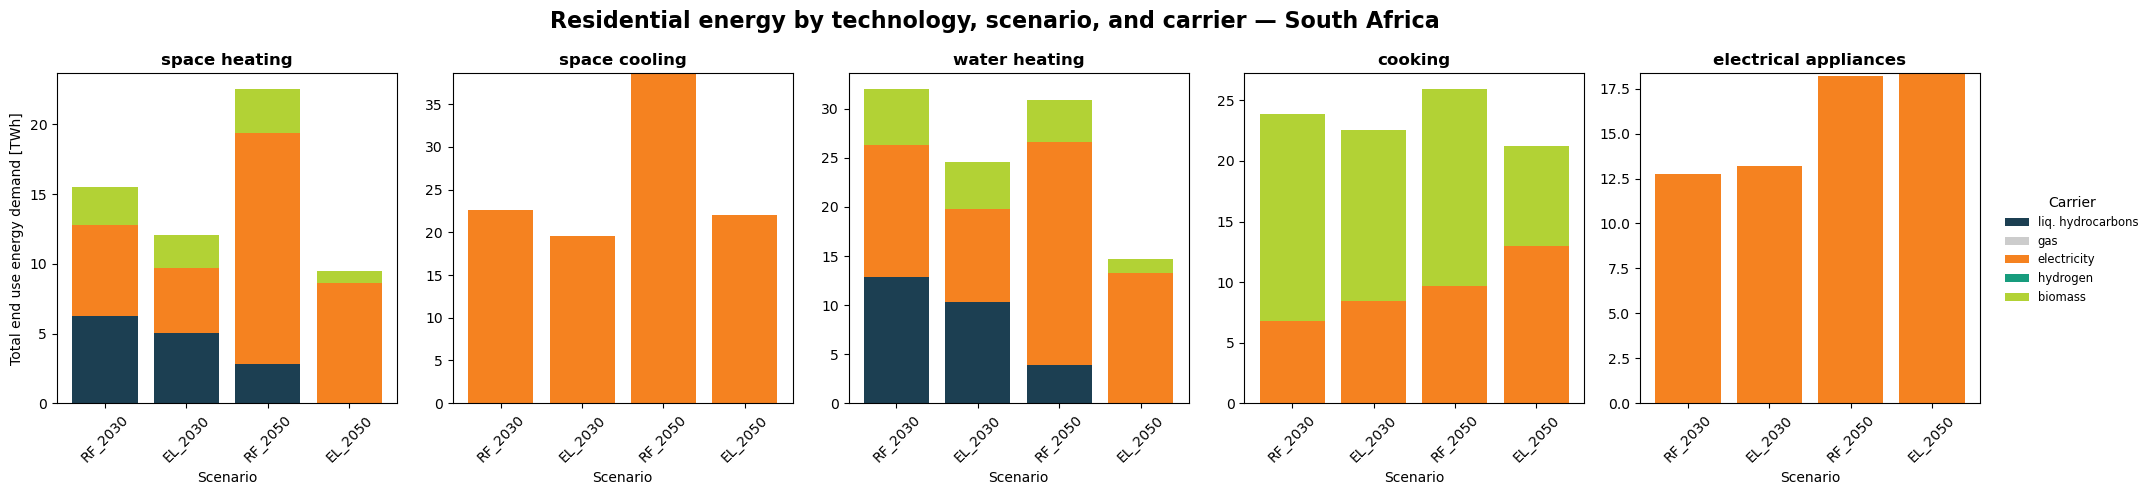

C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence thi

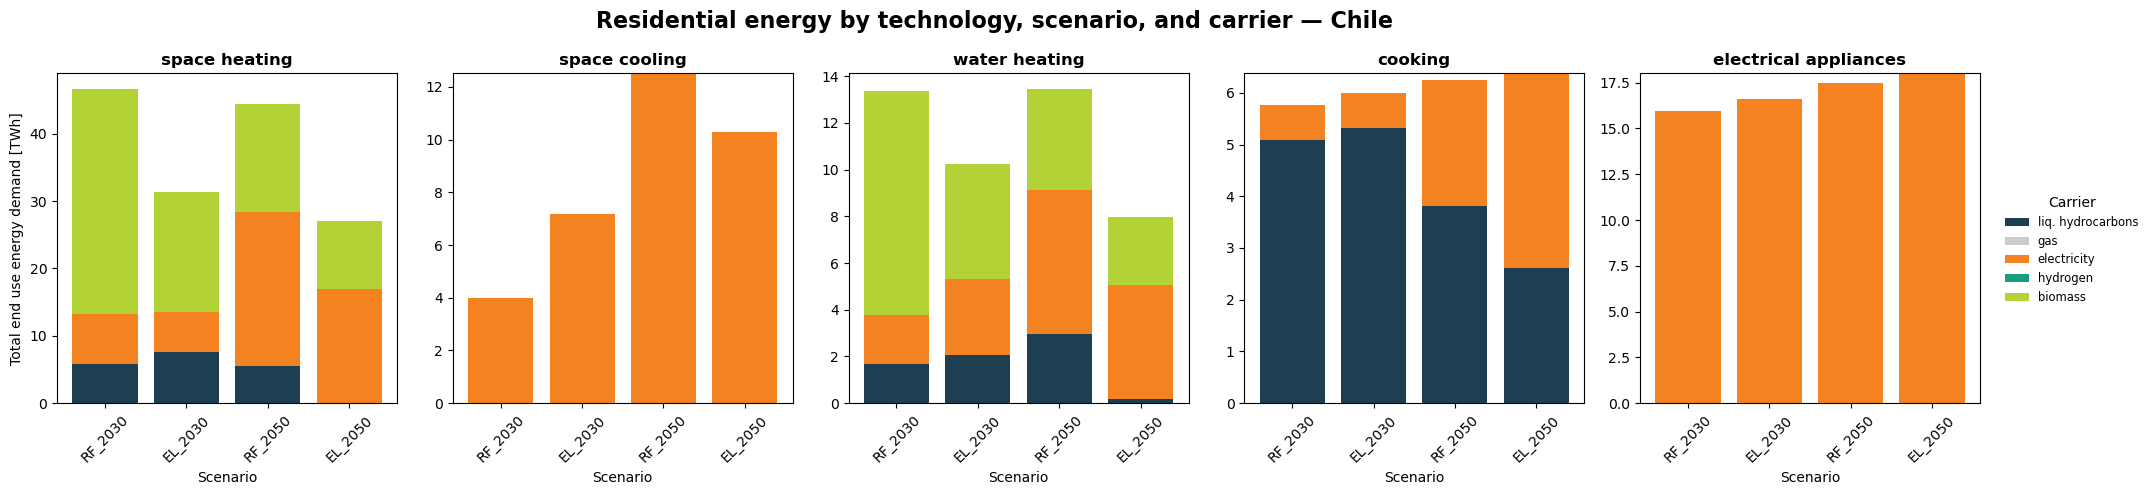

C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence thi

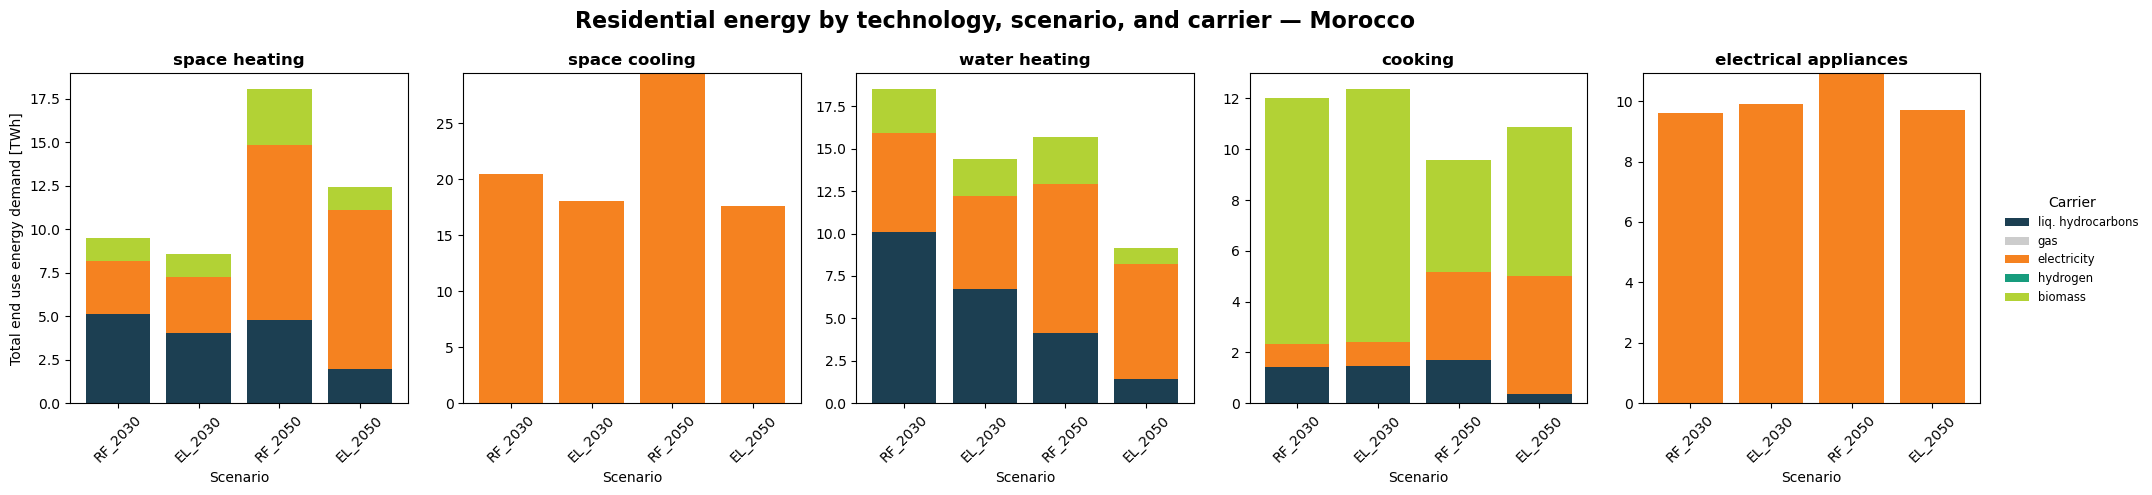

C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
C:\Users\eduque\AppData\Local\Temp\ipykernel_30788\537359612.py:25: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence thi

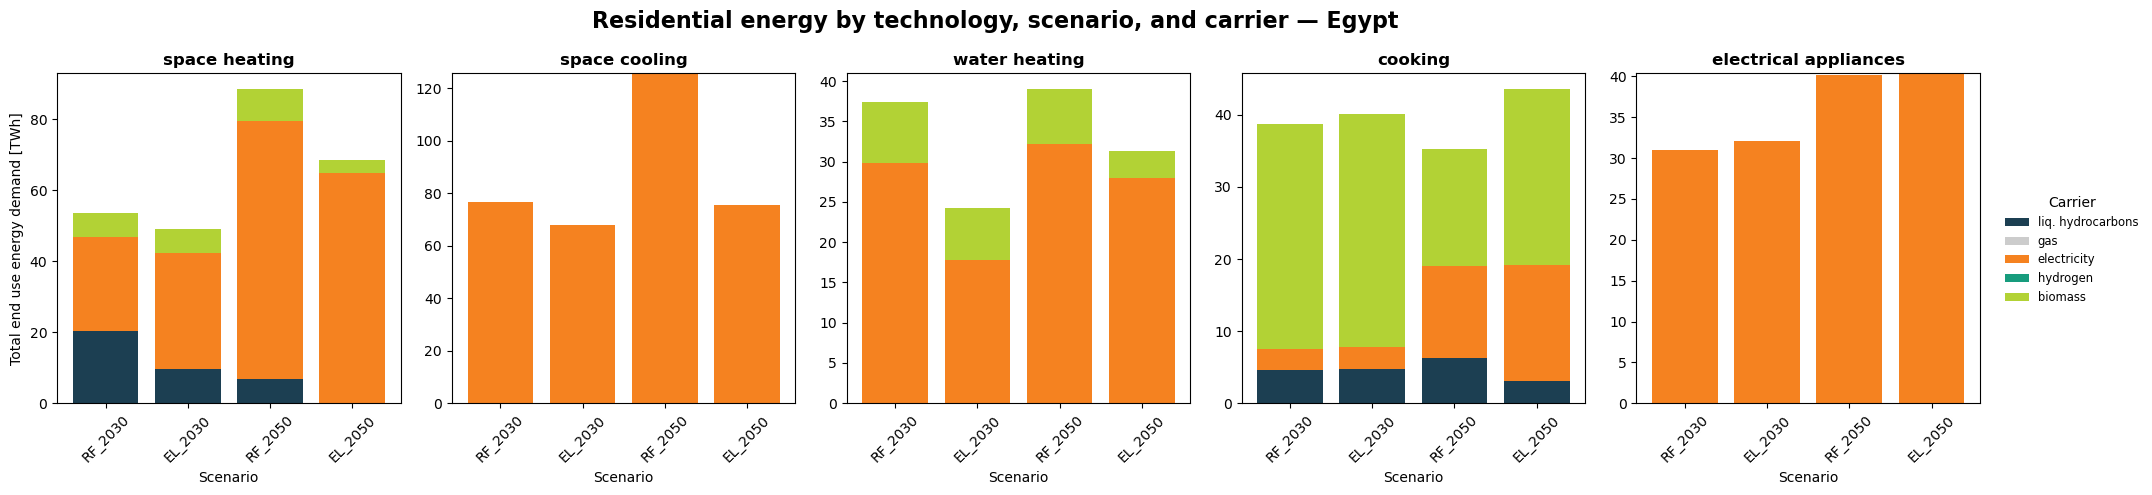

In [13]:
countries = df_long['country'].unique()
country_dic = {"CL": "Chile", "EG": "Egypt", "MA": "Morocco", "ZA": "South Africa"}
carrier_order = df_long["carrier"].unique()
scenario_order = df_long["scenario"].unique()
tech_order = tech_cols  # or sorted(df_long['technology'].unique())


residential_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
}

colors = [residential_colors.get(col, "#cccccc") for col in carrier_order]

for cty in countries:
    d = df_long[df_long['country'] == cty]
    fig, axs = plt.subplots(1, len(tech_order), figsize=(4*len(tech_order), 5), sharey=False)
    for i, tech in enumerate(tech_order):
        ax = axs[i]
        d_tech = d[d['technology'] == tech].copy()
        d_tech['scenario'] = pd.Categorical(d_tech['scenario'], categories=scenario_order, ordered=True)
        pivot = d_tech.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum').fillna(0)
        for carrier in carrier_order:
            if carrier not in pivot.columns:
                pivot[carrier] = 0
        pivot = pivot[carrier_order]
        bottom = np.zeros(len(pivot.index))
        for idx, carrier in enumerate(carrier_order):
            values = pivot[carrier].values
            ax.bar(pivot.index, values, bottom=bottom, color=colors[idx], label=carrier)
            bottom += values
        ax.set_title(tech, fontsize=12, weight='bold')
        ax.set_xlabel('Scenario')
        if i == 0:
            ax.set_ylabel('Total end use energy demand [TWh]')
        ax.tick_params(axis='x', rotation=45)
    full_name = country_dic.get(cty, cty)
    fig.suptitle(f"Residential energy by technology, scenario, and carrier — {full_name}", fontsize=16, weight='bold')
    fig.legend(carrier_order, title="Carrier", loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='small', frameon=False)

    plt.tight_layout()
    plt.show()